# Community Detection Across the Full History

**Assignment deliverables:** (1) run community detection across the full historical period, (2) track the number and strength of communities over time, and (3) chart disagreement between detected communities and official sectors. Outputs include a **cluster feature table**, **membership table**, and **sector comparison charts**.

**Method:** Reuse Brandon's/Week 2's 60-trading-day rolling correlation, absolute correlation **> 0.55**, undirected unweighted NetworkX graph, isolated stocks removed, and greedy modularity communities. Default evaluation is **every 20 trading days over the entire available history**, plus the final date. This covers the full history but **does not run every trading day**; set `STEP_TRADING_DAYS = 1` for daily analysis (potentially very slow). No findings are assumed before execution.

## 1. Environment and configuration

Run from `RGBFS/` or `RGBFS/notebooks/` in VS Code. Install missing packages with `python -m pip install pandas numpy matplotlib networkx scikit-learn pyarrow`. The repo's own `src` modules must be present.

In [1]:
from pathlib import Path
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from networkx.algorithms.community import greedy_modularity_communities, modularity
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

root = Path.cwd().resolve()
if not (root / 'src').exists() and (root.parent / 'src').exists():
    root = root.parent
if not (root / 'src').exists():
    raise FileNotFoundError('Open this notebook from RGBFS/ or RGBFS/notebooks/.')
sys.path.insert(0, str(root))
from src.windows import correlation_at
from src import returns as rt

WINDOW = 60
THRESHOLD = 0.55
STEP_TRADING_DAYS = 20  # 1 = every trading day (much slower); 5 = weekly; 20 ≈ monthly
MIN_MATCHED_SECTOR_STOCKS = 10
SECTOR_FILE = None  # Example: root / 'data' / 'processed' / 'sector_mapping.csv'
OUTPUT_DIR = root / 'notebooks' / 'outputs' / 'grace_week3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Repository:', root, '\nOutput folder:', OUTPUT_DIR)

Repository: C:\Users\dayan\Downloads\RGBFS 
Output folder: C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week3


## 2. Understand and load the data

`rt.load_returns()` provides a **dates × ticker symbols** table of daily stock returns. Each row is a trading date; each column is a stock; each value is its daily return, possibly missing when data is unavailable. A 60-row rolling window is used to compute correlations. We keep the available historical span and do **not** forward-fill returns.

**Sector data (optional for network analysis, required for sector comparison):** `data/processed/sector_mapping.csv` with `ticker,sector`, one ticker per row. A `symbol` column is also accepted in place of `ticker`; `gics_sector` is accepted in place of `sector`. Example:

```csv
ticker,sector
AAPL,information_technology
JPM,financials
XOM,energy
```

These are illustrative records, **not a verified historical sector mapping**. Historical sector membership/classifications can change; a single mapping applied to all dates is an approximation. In particular, modern `real_estate` and `communication_services` classifications are not equivalent to the 2008 GICS structure. For rigorous date-specific comparison, use a dated sector-history dataset and modify the lookup accordingly.

In [2]:
try:
    rets = rt.load_returns()
    print('Loaded using src.returns.load_returns()')
except Exception as exc:
    fallback = root / 'data' / 'processed' / 'returns_daily.parquet'
    if not fallback.exists():
        raise RuntimeError('Returns loader failed and fallback file is missing. Generate or copy data/processed/.') from exc
    warnings.warn(f'Using fallback parquet because loader failed: {exc}')
    rets = pd.read_parquet(fallback)
if not isinstance(rets, pd.DataFrame):
    raise TypeError('Expected returns to be a pandas DataFrame.')
rets = rets.copy()
rets.index = pd.to_datetime(rets.index)
rets = rets.loc[~rets.index.isna()].sort_index()
rets = rets.loc[~rets.index.duplicated(keep='last')]
rets.columns = rets.columns.astype(str).str.strip()
rets = rets.apply(pd.to_numeric, errors='coerce')
if len(rets) < WINDOW:
    raise ValueError(f'Need at least {WINDOW} rows; got {len(rets)}.')
print(f'Returns: {rets.shape[0]:,} trading days × {rets.shape[1]:,} stocks')
print('Date range:', rets.index.min().date(), 'to', rets.index.max().date())
display(rets.iloc[:5, :6])

Loaded using src.returns.load_returns()
Returns: 5,491 trading days × 977 stocks
Date range: 2005-01-03 to 2026-10-29


,A,AABA,AAL,AAP,AAPL,ABBV
Date,,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-04,-0.026382,NaN,NaN,NaN,0.010270,NaN
2005-01-05,-0.000430,NaN,NaN,NaN,0.008758,NaN
2005-01-06,-0.021945,NaN,NaN,NaN,0.000775,NaN
2005-01-07,-0.000880,NaN,NaN,NaN,0.072811,NaN


## 3. Load sector classifications and validate coverage

Sector mapping is **not needed** to compute communities. If unavailable, sector scores/charts are skipped with an explicit message. When present, labels are normalized only for whitespace/case; historical correctness must be verified separately.

In [3]:
candidates = [root / 'data/processed/sectors_2008.csv',
              root / 'data/processed/sector_mapping.csv',
              root / 'data/processed/sectors.csv',
              root / 'data/raw/sectors.csv']
sector_path = Path(SECTOR_FILE) if SECTOR_FILE is not None else next((p for p in candidates if p.exists()), None)
sector_lookup = None
if sector_path is None or not sector_path.exists():
    print('No sector mapping found. Community results will run; sector comparison will be unavailable.')
else:
    raw = pd.read_csv(sector_path)
    names = {str(c).strip().lower(): c for c in raw.columns}
    ticker_col = next((names[k] for k in ('ticker', 'symbol', 'tic') if k in names), None)
    sector_col = next((names[k] for k in ('sector', 'gics_sector', 'gics sector') if k in names), None)
    if ticker_col is None or sector_col is None:
        raise ValueError(f'Sector file needs ticker/symbol and sector columns; found {list(raw.columns)}')
    sectors = raw[[ticker_col, sector_col]].rename(columns={ticker_col:'ticker',sector_col:'sector'}).copy()
    sectors['ticker'] = sectors['ticker'].astype('string').str.strip()
    sectors['sector'] = sectors['sector'].astype('string').str.strip().str.lower()
    sectors = sectors.replace({'': pd.NA}).dropna(subset=['ticker', 'sector'])
    duplicate_count = int(sectors['ticker'].duplicated().sum())
    if duplicate_count:
        warnings.warn(f'{duplicate_count} duplicate ticker records: using first. Confirm date-specific sector history!')
    sectors = sectors.drop_duplicates(subset='ticker', keep='first')
    sector_lookup = sectors.set_index('ticker')['sector'].to_dict()
    print('Sector file:', sector_path)
    print('Unique sector tickers:', len(sector_lookup))
    print('Return-column matches:', sum(t in sector_lookup for t in rets.columns), '/', len(rets.columns))
    display(sectors.head(10))

Sector file: C:\Users\dayan\Downloads\RGBFS\data\processed\sector_mapping.csv
Unique sector tickers: 361
Return-column matches: 351 / 977


,ticker,sector
0,A,health_care
1,AA,materials
2,AAPL,information_technology
3,ABC,health_care
4,ABT,health_care
5,ADBE,information_technology
6,ADI,information_technology
7,ADM,consumer_staples
8,ADP,industrials
9,ADSK,information_technology


## 4. Rolling evaluation dates and graph construction

The first eligible evaluation date is the 60th trading date. All later dates are sampled at the configured interval, **including the final trading date**. The `correlation_at` function is called once per evaluation date. For a graph, connect two stocks if the absolute correlation is strictly greater than 0.55; remove self-loops and isolates. Missing correlations do not create edges.

**Runtime:** A dense network can make greedy modularity expensive. Test `STEP_TRADING_DAYS = 60` for a faster first pass, then 20 or 5, and finally 1 only if needed. The notebook logs progress and saves intermediate results at the end.

In [4]:
def make_graph(corr_matrix, threshold=THRESHOLD):
    if not isinstance(corr_matrix, pd.DataFrame):
        raise TypeError(
            'correlation_at must return a pandas DataFrame.'
        )

    # Create an independent copy
    clean = pd.DataFrame(
        corr_matrix.to_numpy(copy=True),
        index=corr_matrix.index,
        columns=corr_matrix.columns
    )
    clean = clean.replace([np.inf, -np.inf], np.nan)

    # Create adjacency matrix
    adjacency = clean.abs().gt(threshold).fillna(False)

    # Create a writable NumPy array
    adj_array = adjacency.to_numpy(copy=True)
    np.fill_diagonal(adj_array, False)

    # Build network graph
    graph = nx.from_numpy_array(adj_array.astype('int8'))

    # Preserve ticker symbols
    graph = nx.relabel_nodes(
        graph,
        dict(enumerate(adjacency.index))
    )

    # Remove isolated stocks
    graph.remove_nodes_from(list(nx.isolates(graph)))

    return graph

if STEP_TRADING_DAYS < 1:
    raise ValueError('STEP_TRADING_DAYS must be >= 1')
positions = list(range(WINDOW - 1, len(rets), STEP_TRADING_DAYS))
if positions[-1] != len(rets) - 1:
    positions.append(len(rets) - 1)
evaluation_dates = rets.index[positions]
print(f'{len(evaluation_dates)} evaluation dates covering {evaluation_dates[0].date()}–{evaluation_dates[-1].date()}')
print('Frequency: every', STEP_TRADING_DAYS, 'trading day(s) plus last day')

273 evaluation dates covering 2005-03-30–2026-10-29
Frequency: every 20 trading day(s) plus last day


In [5]:
# Check complete-data coverage across the full history

coverage = []

for end_date in evaluation_dates:
    block = rets.loc[:end_date].tail(60)

    complete_stocks = int(block.notna().all().sum())

    coverage.append({
        "date": end_date,
        "complete_stocks": complete_stocks
    })

coverage_df = pd.DataFrame(coverage)

print(coverage_df.describe())
print("\nFirst 10 windows:")
print(coverage_df.head(10))

print("\nMaximum complete stocks:",
      coverage_df["complete_stocks"].max())

                             date  complete_stocks
count                         273       273.000000
mean   2016-01-17 13:27:01.978000       378.395604
min           2005-03-30 00:00:00         0.000000
25%           2010-08-23 00:00:00       323.000000
50%           2016-01-19 00:00:00       370.000000
75%           2021-06-14 00:00:00       444.000000
max           2026-10-29 00:00:00       499.000000
std                           NaN        74.412090

First 10 windows:
        date  complete_stocks
0 2005-03-30                0
1 2005-04-27              259
2 2005-05-25              259
3 2005-06-23              260
4 2005-07-22              260
5 2005-08-19              260
6 2005-09-19              260
7 2005-10-17              262
8 2005-11-14              266
9 2005-12-13              266

Maximum complete stocks: 499


## 5. Run community detection across the history

For each date, record `n_communities` and **modularity** (the community-strength measure), plus graph size/density, largest cluster share, sector coverage, and sector alignment metrics. Modularity is not directly comparable without considering network density and the changing stock universe. A graph with zero edges has no detected communities and undefined modularity (stored as `NaN`).

ARI/NMI compare two partitions on **matched stocks only**; a low score means poor agreement with the chosen sector labels, not necessarily that clustering is incorrect.

In [6]:
feature_rows = []
membership_rows = []
start_time = time.perf_counter()
for i, end_date in enumerate(evaluation_dates, start=1):
    try:
        corr = correlation_at(rets, end=end_date.strftime('%Y-%m-%d'), window=WINDOW)
        G = make_graph(corr)
        groups = list(greedy_modularity_communities(G)) if G.number_of_edges() else []
        groups = sorted(groups, key=lambda group: (-len(group), sorted(map(str, group))[0]))
        score = float(modularity(G, groups)) if groups and G.number_of_edges() else np.nan
        labels = {str(ticker): community_id for community_id, group in enumerate(groups, start=1)
                  for ticker in group}
        aligned = [(ticker, label, sector_lookup[ticker]) for ticker, label in labels.items()
                   if sector_lookup is not None and ticker in sector_lookup]
        matched = len(aligned)
        ari = adjusted_rand_score([x[2] for x in aligned], [x[1] for x in aligned]) if matched >= MIN_MATCHED_SECTOR_STOCKS else np.nan
        nmi = normalized_mutual_info_score([x[2] for x in aligned], [x[1] for x in aligned]) if matched >= MIN_MATCHED_SECTOR_STOCKS else np.nan
        date_str = end_date.strftime('%Y-%m-%d')
        for ticker, label in labels.items():
            membership_rows.append({'date': date_str, 'ticker': ticker, 'community': label,
                                    'sector': sector_lookup.get(ticker, pd.NA) if sector_lookup is not None else pd.NA})
        feature_rows.append({'date': date_str, 'n_stocks': G.number_of_nodes(),
                             'n_edges': G.number_of_edges(), 'density': nx.density(G),
                             'n_communities': len(groups), 'modularity': score,
                             'largest_community_size': max(map(len, groups), default=0),
                             'largest_community_share': max(map(len, groups), default=0) / G.number_of_nodes() if G.number_of_nodes() else np.nan,
                             'sector_matched': matched,
                             'sector_coverage': matched / G.number_of_nodes() if G.number_of_nodes() else np.nan,
                             'sector_ari': ari, 'sector_nmi': nmi})
    except ValueError as exc:
        if "complete data" in str(exc):
            print(f"Skipping {end_date.date()}: {exc}")
            continue
        raise
    if i == 1 or i % 10 == 0 or i == len(evaluation_dates):
        print(f'Processed {i}/{len(evaluation_dates)} windows; latest={end_date.date()}; elapsed={time.perf_counter()-start_time:.1f}s', flush=True)

features = pd.DataFrame(feature_rows)
features['date'] = pd.to_datetime(features['date'])
features = features.sort_values('date').reset_index(drop=True)
memberships = pd.DataFrame(membership_rows, columns=['date','ticker','community','sector'])
features.to_csv(OUTPUT_DIR / 'cluster_features.csv', index=False)
memberships.to_csv(OUTPUT_DIR / 'community_memberships.csv', index=False)
print('Saved:', OUTPUT_DIR / 'cluster_features.csv')
print('Saved:', OUTPUT_DIR / 'community_memberships.csv')
display(features.head())
display(features.tail())

Skipping 2005-03-30: Only 0 stocks have complete data in that window (min 100)
Processed 10/273 windows; latest=2005-12-13; elapsed=1.2s
Processed 20/273 windows; latest=2006-09-29; elapsed=2.6s
Processed 30/273 windows; latest=2007-07-19; elapsed=4.3s
Processed 40/273 windows; latest=2008-05-05; elapsed=10.6s
Processed 50/273 windows; latest=2009-02-19; elapsed=22.6s
Processed 60/273 windows; latest=2009-12-03; elapsed=31.8s
Processed 70/273 windows; latest=2010-09-21; elapsed=44.7s
Processed 80/273 windows; latest=2011-07-07; elapsed=50.3s
Processed 90/273 windows; latest=2012-04-23; elapsed=68.5s
Processed 100/273 windows; latest=2013-02-08; elapsed=75.8s
Processed 110/273 windows; latest=2013-11-22; elapsed=82.8s
Processed 120/273 windows; latest=2014-09-11; elapsed=87.7s
Processed 130/273 windows; latest=2015-06-29; elapsed=96.1s
Processed 140/273 windows; latest=2016-04-14; elapsed=110.6s
Processed 150/273 windows; latest=2017-01-30; elapsed=118.1s
Processed 160/273 windows; late

,date,n_stocks,n_edges,density,n_communities,modularity,largest_community_size,largest_community_share,sector_matched,sector_coverage,sector_ari,sector_nmi
0,2005-04-27,213,1843,0.081628,14,0.339723,80,0.375587,182,0.854460,0.215109,0.394012
1,2005-05-25,228,2494,0.096375,9,0.292337,97,0.425439,192,0.842105,0.195600,0.395430
2,2005-06-23,219,2233,0.093544,7,0.275789,72,0.328767,188,0.858447,0.187596,0.378693
3,2005-07-22,206,1061,0.050249,11,0.372155,73,0.354369,175,0.849515,0.167228,0.422601
4,2005-08-19,195,669,0.035369,16,0.640679,68,0.348718,169,0.866667,0.238775,0.466929


,date,n_stocks,n_edges,density,n_communities,modularity,largest_community_size,largest_community_share,sector_matched,sector_coverage,sector_ari,sector_nmi
267,2026-07-21,446,3847,0.038767,23,0.577832,128,0.286996,223,0.500000,0.113785,0.401076
268,2026-08-18,459,4110,0.039102,24,0.535040,116,0.252723,232,0.505447,0.190849,0.447634
269,2026-09-16,443,4286,0.043778,27,0.446922,141,0.318284,223,0.503386,0.208005,0.460235
270,2026-10-14,444,2568,0.026112,32,0.628228,154,0.346847,225,0.506757,0.215330,0.506664
271,2026-10-29,457,3470,0.033303,22,0.549147,125,0.273523,230,0.503282,0.319668,0.536354


### Interpretation: full-history community detection

The analysis evaluated **273** dates spanning March 30, 2005, to October 29, 2026, at intervals of **20 trading days**, plus the final available date. **272 windows produced valid networks**; March 30, 2005, was excluded because no stocks met the shared `correlation_at()` function's complete-data requirement (minimum 100 stocks). The successful analysis therefore spans **April 27, 2005, to October 29, 2026**.

Across the valid windows, the number of stocks retained in the correlation networks ranged from **157 to 478**. These counts refer to graph nodes **after isolated stocks were removed**, not the total 977 ticker columns in the source returns table. Community memberships are saved by date and ticker, and the cluster feature table contains network size, density, number of communities, modularity, and sector-comparison metrics. The algorithm was applied consistently to eligible windows; these results should not be interpreted as daily community detection because the evaluation interval is approximately monthly.


## 6. Plot number of communities and cluster strength over time

A rise in `n_communities` means the algorithm partitions the sampled network into more groups. Higher modularity generally indicates more distinct community structure **within that graph**. Interpret changes together with node count, graph density, and the number of isolates excluded.

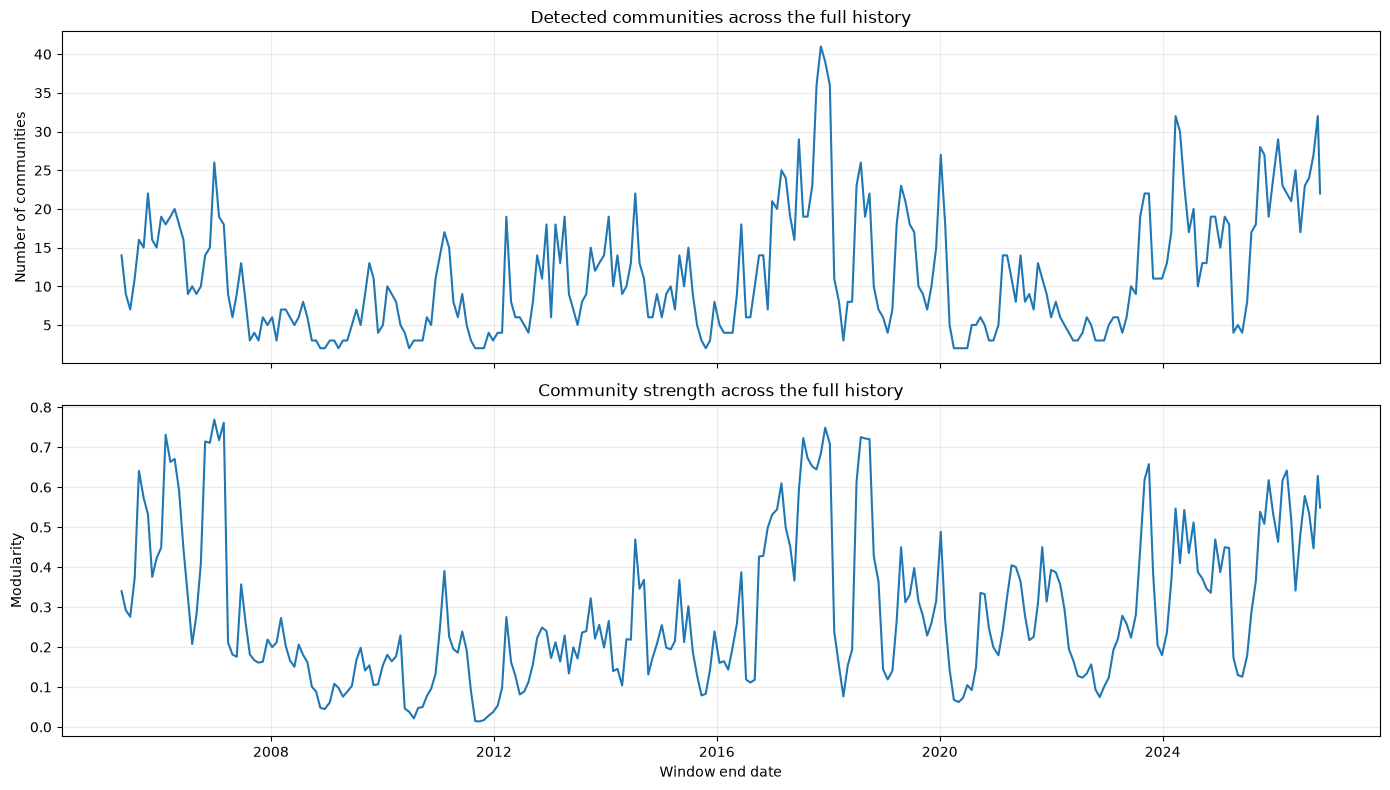

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(features['date'], features['n_communities'], linewidth=1.5)
axes[0].set(title='Detected communities across the full history', ylabel='Number of communities')
axes[0].grid(alpha=.25)
axes[1].plot(features['date'], features['modularity'], linewidth=1.5)
axes[1].set(title='Community strength across the full history', ylabel='Modularity', xlabel='Window end date')
axes[1].grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'community_count_and_modularity_over_time.png', dpi=160, bbox_inches='tight')
plt.show()

### Interpretation — changes in community count and strength

The number of detected communities varied from **2 to 41**, with a **median of 9** across 272 valid windows. This wide range shows that the network's partition structure changed substantially over the observed history. **Modularity**, a measure of how much the detected partition concentrates edges within communities relative to a network-based baseline, ranged from **0.0139 to 0.7690**, with a **median of 0.2326**. Higher modularity indicates more distinct community structure under this metric; it does not, by itself, establish stronger economic or causal relationships.

Interpret the time-series plots together: changes in the number of communities need not coincide with changes in modularity. The results are sensitive to the fixed **0.55 absolute-correlation threshold**, the changing number of eligible stocks, and the exclusion of isolates. Consequently, apparent historical differences may reflect both market relationships and changing network coverage. The notebook does not establish that any specific market event caused a change in clustering.


## 7. Chart disagreement with official sectors

ARI is approximately 1 for identical partitions (0 is chance-level agreement; negative values are possible). NMI ranges from 0 to 1. **Lower values indicate more disagreement**. The chart includes sector coverage to show when the comparison is based on fewer matched stocks. If the mapping is missing, the notebook still produces the other deliverables and explains what to supply.

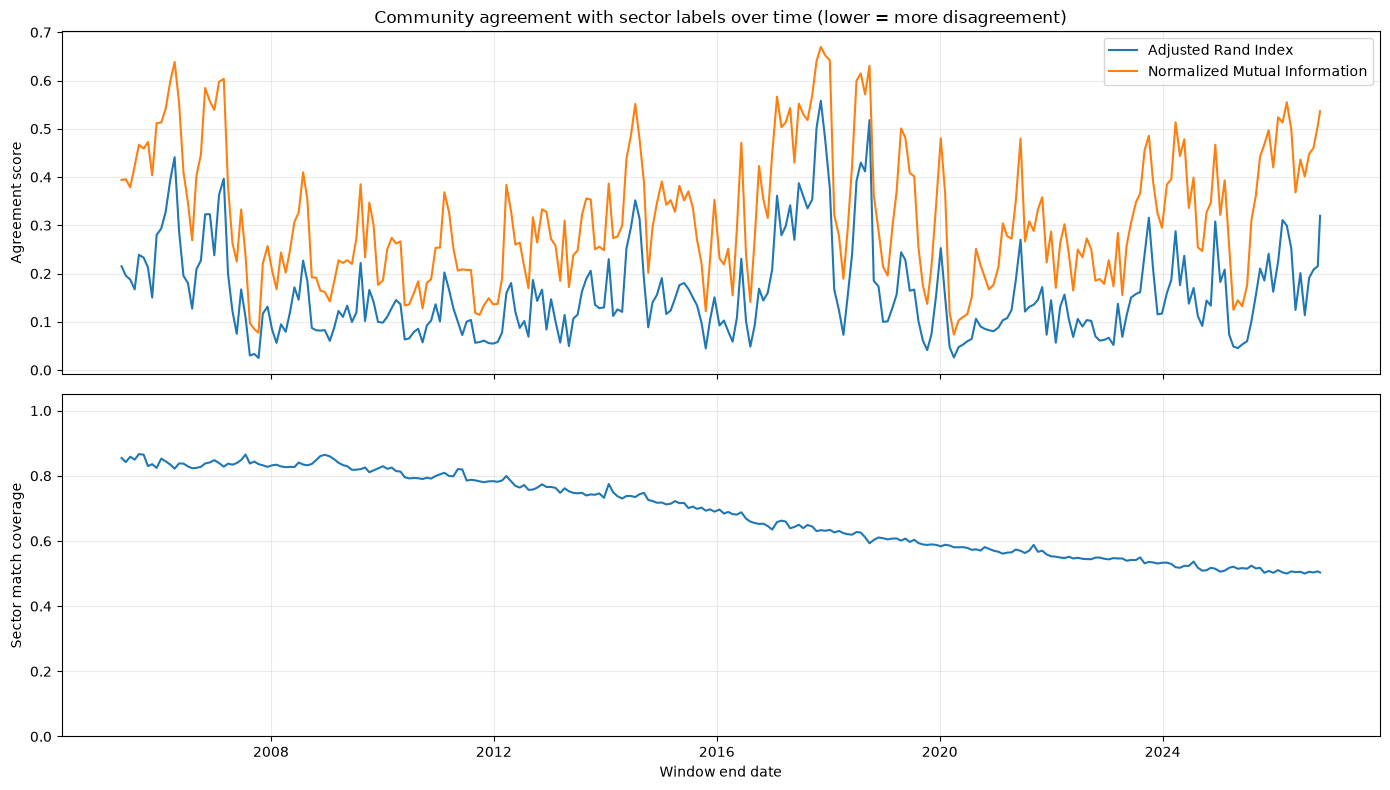

Dates with lowest ARI (most sector disagreement among scored windows):


,date,n_stocks,sector_matched,sector_coverage,sector_ari,sector_nmi
31,2007-10-12,274,229,0.835766,0.025072,0.077326
188,2020-04-03,434,252,0.580645,0.026060,0.073673
29,2007-08-16,271,227,0.837638,0.030230,0.097160
30,2007-09-14,275,232,0.843636,0.033374,0.084982
182,2019-10-11,415,244,0.587952,0.041356,0.137038
132,2015-10-21,368,255,0.692935,0.044860,0.121751
252,2025-05-08,478,246,0.514644,0.045493,0.144724
189,2020-05-04,434,252,0.580645,0.047573,0.102877
187,2020-03-06,425,249,0.585882,0.047599,0.119746
142,2016-08-08,367,242,0.659401,0.048508,0.141108


In [8]:
sector_results = features[['date', 'n_stocks', 'sector_matched', 'sector_coverage', 'sector_ari', 'sector_nmi']].copy()
sector_results.to_csv(OUTPUT_DIR / 'sector_alignment_over_time.csv', index=False)
if sector_lookup is None:
    print('SECTOR COMPARISON NOT AVAILABLE: add data/processed/sector_mapping.csv (ticker,sector) and rerun.')
elif sector_results['sector_ari'].notna().sum() == 0:
    print('Sector mapping exists, but fewer than', MIN_MATCHED_SECTOR_STOCKS, 'stocks match per window. Verify ticker formatting.')
else:
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(sector_results['date'], sector_results['sector_ari'], label='Adjusted Rand Index')
    axes[0].plot(sector_results['date'], sector_results['sector_nmi'], label='Normalized Mutual Information')
    axes[0].set(title='Community agreement with sector labels over time (lower = more disagreement)', ylabel='Agreement score')
    axes[0].legend()
    axes[0].grid(alpha=.25)
    axes[1].plot(sector_results['date'], sector_results['sector_coverage'])
    axes[1].set(ylabel='Sector match coverage', xlabel='Window end date', ylim=(0, 1.05))
    axes[1].grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'sector_disagreement_over_time.png', dpi=160, bbox_inches='tight')
    plt.show()
    print('Dates with lowest ARI (most sector disagreement among scored windows):')
    display(sector_results.dropna(subset=['sector_ari']).nsmallest(10, 'sector_ari'))

### Interpretation: agreement and disagreement with sectors

The sector file contained **361 unique tickers**, of which **351** matched columns in the full returns dataset. Match rates for each *constructed network* are lower and vary by date; the **median sector coverage was 69.0%**. Among scored windows, the **median Adjusted Rand Index (ARI) was 0.1346** and the **median Normalized Mutual Information (NMI) was 0.2977**. These values indicate that detected correlation communities generally had **limited correspondence** with the supplied sector labels, although the extent of agreement varies over time.

The ARI/NMI plot shows changes in partition agreement, while the coverage plot indicates how much of each network was available for the comparison. Interpret low agreement with care when sector coverage is incomplete. **Critical historical limitation:** the notebook applies a single ticker-to-sector mapping to every date. It has not verified that these labels were in effect for each historical window; sector definitions and index membership can change. The sector comparison is therefore **approximate**, not a date-accurate validation against official historical classifications.


## 8. Sector composition and disagreement by sector

For each window, compute how each sector is distributed across detected communities. `dominant_community_share` is the fraction of matched stocks in that sector that belong to its most common detected community. **Lower share means that sector is split across more communities**. This is a descriptive diagnostic, not an official classification accuracy score; community IDs can switch meaning between dates.

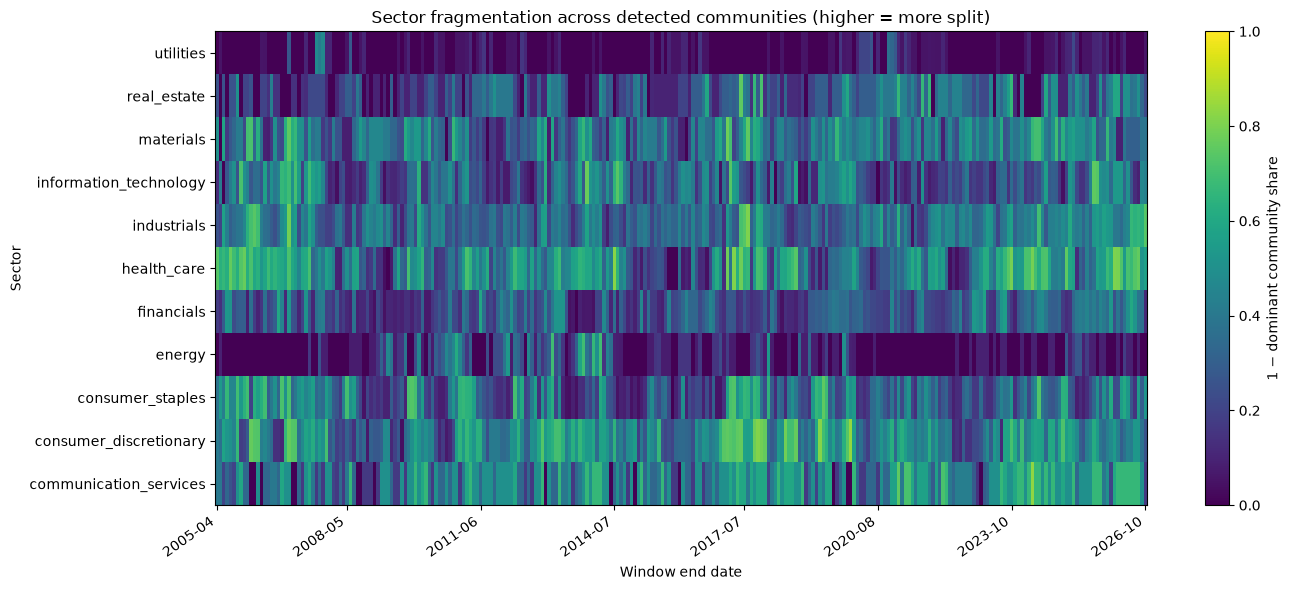

In [9]:
sector_breakdown = pd.DataFrame(columns=['date', 'sector', 'matched_stocks', 'communities_represented', 'dominant_community_share', 'sector_fragmentation'])
matched_members = memberships.dropna(subset=['sector'])
if not matched_members.empty:
    breakdown_rows = []
    for (date, sector), group in matched_members.groupby(['date', 'sector'], sort=True):
        counts = group['community'].value_counts()
        top_share = counts.iloc[0] / counts.sum()
        breakdown_rows.append({'date': date, 'sector': sector, 'matched_stocks': len(group),
                               'communities_represented': len(counts),
                               'dominant_community_share': top_share,
                               'sector_fragmentation': 1 - top_share})
    sector_breakdown = pd.DataFrame(breakdown_rows)
sector_breakdown.to_csv(OUTPUT_DIR / 'sector_fragmentation_over_time.csv', index=False)
if not sector_breakdown.empty:
    sector_breakdown['date'] = pd.to_datetime(sector_breakdown['date'])
    pivot = sector_breakdown.pivot(index='date', columns='sector', values='sector_fragmentation')
    fig, ax = plt.subplots(figsize=(14, 6))
    im = ax.imshow(pivot.T.to_numpy(), aspect='auto', interpolation='nearest', vmin=0, vmax=1,
                   extent=[0, len(pivot.index), -0.5, len(pivot.columns)-0.5], origin='lower')
    ax.set_yticks(range(len(pivot.columns)), pivot.columns)
    ticks = np.unique(np.linspace(0, len(pivot.index)-1, min(8, len(pivot.index)), dtype=int))
    ax.set_xticks(ticks + .5, [pivot.index[j].strftime('%Y-%m') for j in ticks], rotation=35, ha='right')
    ax.set(xlabel='Window end date', ylabel='Sector', title='Sector fragmentation across detected communities (higher = more split)')
    fig.colorbar(im, ax=ax, label='1 − dominant community share')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'sector_fragmentation_heatmap.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print('Sector fragmentation heatmap skipped: no matched sector labels.')

### Interpretation: sector fragmentation heatmap

For each date and sector with matched stocks, the notebook calculates **sector fragmentation = 1 − (share of that sector's matched stocks in its largest detected community)**. A value near **0** means most matched stocks in that sector appear in one detected community; higher values mean they are spread across several communities. The heatmap visualizes how this within-sector splitting changes across evaluated dates.

Fragmentation is **not the same as ARI or NMI**: it measures how individual sectors are split, whereas ARI/NMI compare the overall partitions. Sector sizes, matched-stock coverage, and the use of a non-date-specific sector file can all affect the heatmap. The plotted values are descriptive and should not be treated as proof that official sectors are incorrect.


## 9. Data-quality checks and automatically generated interpretation

The output below reports **actual calculated values** after execution. Compare network sizes and sector coverage before drawing conclusions. A single mapping across decades can introduce label drift; avoid describing it as exact historical GICS agreement.

In [10]:
print('FULL-HISTORY SUMMARY')
print('Evaluation windows:', len(features))
print('Coverage:', features['date'].min().date(), 'to', features['date'].max().date())
print('Communities — median:', features['n_communities'].median(),
      '| min:', features['n_communities'].min(), '| max:', features['n_communities'].max())
print('Modularity — median:', round(features['modularity'].median(), 4),
      '| min:', round(features['modularity'].min(), 4),
      '| max:', round(features['modularity'].max(), 4))
print('Stocks per network — min:', features['n_stocks'].min(), '| max:', features['n_stocks'].max())
if features['sector_ari'].notna().any():
    print('Sector ARI — median:', round(features['sector_ari'].median(), 4))
    print('Sector NMI — median:', round(features['sector_nmi'].median(), 4))
    print('Sector coverage — median:', f"{features['sector_coverage'].median():.1%}")
else:
    print('Sector agreement: not available; add a verified sector mapping file.')
print('\nFiles generated:')
for p in sorted(OUTPUT_DIR.glob('*')):
    print(' -', p.relative_to(root))

FULL-HISTORY SUMMARY
Evaluation windows: 272
Coverage: 2005-04-27 to 2026-10-29
Communities — median: 9.0 | min: 2 | max: 41
Modularity — median: 0.2326 | min: 0.0139 | max: 0.769
Stocks per network — min: 157 | max: 478
Sector ARI — median: 0.1346
Sector NMI — median: 0.2977
Sector coverage — median: 69.0%

Files generated:
 - notebooks\outputs\grace_week3\cluster_features.csv
 - notebooks\outputs\grace_week3\community_count_and_modularity_over_time.png
 - notebooks\outputs\grace_week3\community_memberships.csv
 - notebooks\outputs\grace_week3\sector_alignment_over_time.csv
 - notebooks\outputs\grace_week3\sector_disagreement_over_time.png
 - notebooks\outputs\grace_week3\sector_fragmentation_heatmap.png
 - notebooks\outputs\grace_week3\sector_fragmentation_over_time.csv


## 10. Final conclusion

This Week 3 analysis extended the Week 2 single-window study into a longitudinal assessment of stock-correlation communities. Using **60-trading-day rolling windows**, a **0.55 absolute-correlation threshold**, and **greedy modularity community detection**, the notebook evaluated **273 dates** at approximately 20-trading-day intervals. **272 dates were successfully analyzed** between **April 27, 2005, and October 29, 2026**; the first attempted date, March 30, 2005, was omitted because it lacked enough stocks with complete returns.

The detected networks contained **157–478 stocks** after removing isolated nodes. The number of communities ranged from **2 to 41** (median **9**), while modularity ranged from **0.0139 to 0.7690** (median **0.2326**). These variations demonstrate that the observed network partition structure was **not constant over time**. However, differences in eligible stock coverage and the chosen correlation threshold also influence these results.

The sector comparison found **median ARI = 0.1346** and **median NMI = 0.2977**, with **median network-level sector coverage of 69.0%**. The relatively low agreement suggests that correlation-based communities did not consistently reproduce the supplied sector classifications. The sector-alignment chart and fragmentation heatmap provide complementary views of when and how those classifications differ from detected communities.

**Limitations:** The sector mapping is applied unchanged across the historical period and is **not verified as date-specific**; therefore, comparisons with “official sectors” are approximate. Absolute correlations combine strong positive and negative associations, the network excludes isolates, and the 20-trading-day sampling interval does not capture every daily fluctuation. Community detection identifies patterns of association, not causal explanations for them.

**Week 3 deliverables completed:** a dated **cluster feature table**, dated **community memberships**, a **community-count and modularity chart**, a **sector agreement chart**, and a **sector fragmentation heatmap**. The notebook retains the executed analysis and saved plots. For reproducibility, teammates will need the shared processed returns data and the sector mapping file in their local project environment.
